# Ein Bakterium im Computer

## Was ist Stoffwechsel?

Jede Zelle ist eine winzige chemische Fabrik. Sie nimmt Nahrung auf (zum Beispiel Zucker) und verwandelt sie Schritt für Schritt in Energie und in die Bausteine einer neuen Zelle. Jeder Schritt ist eine **chemische Reaktion**, und jede Reaktion wird von einem **Enzym** durchgeführt. Die Bauanleitung für jedes Enzym steht in einem **Gen**.

```mermaid
flowchart LR
    A[Nahrung<br>Glukose, Sauerstoff, ...] --> B[Reaktionen<br>durch Enzyme ermöglicht]
    B --> C[Bausteine<br>Aminosäuren, DNA, Fette, ...]
    C --> D[Neue Zelle]
    B --> E[Abfall<br>CO2, Wasser, ...]
```

Forschende haben alle bekannten Reaktionen von *E. coli* in einem **Stoffwechselmodell** gesammelt. Heute benutzen wir eine kleine Version davon, das ***E.-coli*-Kernmodell** (*core model*) aus der [BiGG-Datenbank](http://bigg.ucsd.edu/models/e_coli_core).

Führe zuerst die Zelle unten aus; sie stellt die Sprache der Ausgaben ein. Dann lade das Modell.

In [1]:
setLanguage('de')   % Sprache der Ausgaben

Sprache: Deutsch


In [2]:
model = loadEcoli();

Modell geladen: E.-coli-Kernmodell mit 95 Reaktionen, 72 Metaboliten und 137 Genen.


## Ein Blick ins Modell

Jede Reaktion hat eine kurze ID und einen vollen Namen (auf Englisch). Hier sind die ersten zehn:

In [3]:
[model.rxns(1:10), model.rxnNames(1:10)]

ans =
{
  [1,1] = PFK
  [2,1] = PFL
  [3,1] = PGI
  [4,1] = PGK
  [5,1] = PGL
  [6,1] = ACALD
  [7,1] = AKGt2r
  [8,1] = PGM
  [9,1] = PIt2r
  [10,1] = ALCD2x
  [1,2] = Phosphofructokinase
  [2,2] = Pyruvate formate lyase
  [3,2] = Glucose-6-phosphate isomerase
  [4,2] = Phosphoglycerate kinase
  [5,2] = 6-phosphogluconolactonase
  [6,2] = Acetaldehyde dehydrogenase (acetylating)
  [7,2] = 2 oxoglutarate reversible transport via symport
  [8,2] = Phosphoglycerate mutase
  [9,2] = Phosphate reversible transport via symport
  [10,2] = Alcohol dehydrogenase (ethanol)
}



Schauen wir uns eine Reaktion genauer an: **PGK** (Phosphoglyceratkinase). Sie ist einer der Schritte, die Zucker abbauen und dabei Energie in Form von **ATP** herstellen, der „Batterie“ der Zelle.

Die Ausgabe zeigt die Reaktionsgleichung und ganz am Ende das **Gen**, das für ihr Enzym codiert.

In [4]:
printRxnFormula(model, 'rxnAbbrList', 'PGK', 'gprFlag', true);

PGK	3pg_c + atp_c 	<=>	13dpg_c + adp_c 	b2926


`3pg_c + atp_c <=> 13dpg_c + adp_c` bedeutet: 3-Phosphoglycerat und ATP reagieren zu 1,3-Bisphosphoglycerat und ADP. Das `_c` bedeutet „im Cytoplasma“, also im Inneren der Zelle. `_e` würde „außerhalb der Zelle“ bedeuten. `<=>` heißt, dass die Reaktion in beide Richtungen laufen kann.

`b2926` ist die ID des Gens. Sein Name ist *pgk*.

## Wie der Computer Wachstum vorhersagt: Flussbilanzanalyse

Stell dir das Modell wie ein Straßennetz vor: Die Reaktionen sind Straßen, und die Moleküle sind der Verkehr. Wie viel Verkehr über eine Straße fließt, nennt man **Fluss**. Der Computer muss herausfinden, wie viel Verkehr über jede Straße fließt. Dafür hat er drei Regeln:

1. **Nichts staut sich.** Alles, was in der Zelle hergestellt wird, wird auch wieder verbraucht, wie bei einer Badewanne mit offenem Hahn und offenem Abfluss, in der der Wasserstand gleich bleibt.
2. **Grenzen.** Die Zelle kann pro Stunde nur eine begrenzte Menge Nahrung aufnehmen. In unserem Modell: höchstens 10 Einheiten Glukose (Zucker).
3. **Ein Ziel.** Wir nehmen an, dass das Bakterium **so schnell wie möglich wachsen** will. Die Evolution hat Bakterien darin sehr gut gemacht.

Es gibt eine besondere Reaktion, die für „baue eine neue Zelle“ steht: die **Biomasse-Reaktion** `BIOMASS_Ecoli_core_w_GAM`. Sie ist ein Rezept mit allen Bausteinen, die eine neue Zelle braucht. Der Computer sucht die Flüsse, mit denen diese Reaktion so schnell wie möglich läuft.

Diese Methode heißt **Flussbilanzanalyse** (*flux balance analysis*, **FBA**). Für die Suche wird ein mathematisches Verfahren namens *lineare Optimierung* benutzt. Probieren wir es aus:

In [5]:
[growth, solution] = showGrowth(model);

Wachstumsrate: 0.874 pro Stunde (die Zellen verdoppeln sich alle 48 Minuten).


Das Modell sagt vorher, dass sich *E. coli* mit Glukose und genug Sauerstoff etwa alle **48 Minuten** verdoppelt. Im Labor verdoppelt sich *E. coli* je nach Bedingungen alle 20 bis 60 Minuten, die Vorhersage liegt also im richtigen Bereich. Der Computer hat das nur aus der Liste der Reaktionen berechnet!

## Was geht hinein, was kommt heraus?

In [6]:
showExchange(model, solution)

Die Zellen NEHMEN AUF:
  Sauerstoff (O2)                 21.80
  Glukose (Zucker)                10.00
  Ammonium (Stickstoff)            4.77
  Phosphat                         3.21
Die Zellen GEBEN AB:
  Wasser                          29.18
  Kohlendioxid (CO2)              22.81
  H+ (Säure)                      17.53


Die Zahlen sind in mmol pro Gramm Bakterien pro Stunde.

**Frage 1:** Was nimmt *E. coli* auf, und was gibt es ab? Vergleiche das mit dem, was *du* ein- und ausatmest.

✅ **Antwort:** Es nimmt Glukose (Zucker), Sauerstoff, Ammonium (eine Stickstoffquelle) und Phosphat auf. Es gibt Kohlendioxid, Wasser und H⁺ ab. Genau wie wir „verbrennt“ es Zucker mit Sauerstoff und atmet CO₂ und Wasser aus. Stickstoff und Phosphat braucht es, um Proteine und DNA zu bauen.

## Die aktivsten Reaktionen

Über welche Reaktionen fließt am meisten Verkehr? Positive Zahlen heißen, die Reaktion läuft vorwärts, negative Zahlen, sie läuft rückwärts.

  ATPS4r          45.51   ATP synthase (four protons for one ATP)
  CYTBD           43.60   Cytochrome oxidase bd (ubiquinol-8: 2 protons)
  NADH16          38.53   NADH dehydrogenase (ubiquinone-8 & 3 protons)
  EX_h2o_e        29.18   H2O exchange
  H2Ot           -29.18   H2O transport via diffusion
  CO2t           -22.81   CO2 transporter via diffusion
  EX_co2_e        22.81   CO2 exchange
  EX_o2_e        -21.80   O2 exchange
  O2t             21.80   O2 transport  diffusion 
  EX_h_e          17.53   H+ exchange
  PGK            -16.02   Phosphoglycerate kinase
  GAPD            16.02   Glyceraldehyde-3-phosphate dehydrogenase
  PGM            -14.72   Phosphoglycerate mutase
  ENO             14.72   Enolase
  EX_glc__D_e    -10.00   D-Glucose exchange


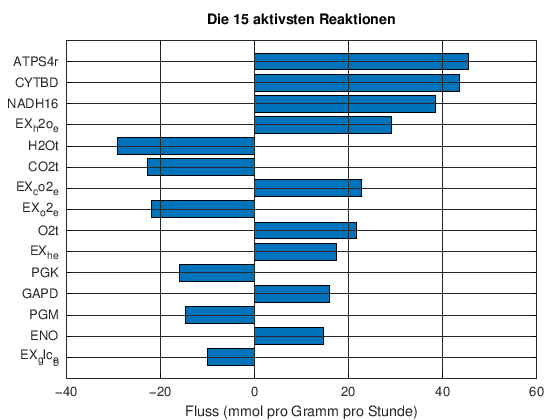

In [7]:
showFluxes(model, solution, 15)

**Frage 2:** Schau dir die Namen in der Liste unter dem Diagramm an. Mehrere der aktivsten Reaktionen haben mit ATP (`ATPS4r` = ATP-Synthase) und mit der Atmung zu tun (`CYTBD` = Cytochrom-Oxidase, `NADH16` = NADH-Dehydrogenase). Warum steckt die Zelle wohl so viel Aufwand in diese Reaktionen?

✅ **Antwort:** Eine neue Zelle zu bauen kostet sehr viel Energie. Diese Reaktionen bilden die **Atmungskette**, die mit Sauerstoff den größten Teil des ATP der Zelle herstellt. ATP ist die Energiewährung, mit der fast alle anderen Reaktionen angetrieben werden.

## Zusammenfassung

* Ein **Stoffwechselmodell** listet alle Reaktionen einer Zelle auf, zusammen mit den Genen dahinter.
* Die **Flussbilanzanalyse** findet die Flüsse, mit denen die Zelle am schnellsten wächst, ohne dass sich etwas staut und ohne dass sie mehr frisst als erlaubt.
* Daraus sagt der Computer die **Wachstumsrate** vorher und was die Zelle **aufnimmt und abgibt**.

In den Aufgaben änderst du die Bedingungen und schaust, wie das Bakterium reagiert. Fang mit `02_exercise_oxygen.ipynb` an.

## Quellen

* **Modell:** das *E.-coli*-Kernmodell (`e_coli_core`) aus BiGG Models. Orth JD, Fleming RMT, Palsson BØ (2010). Reconstruction and use of microbial metabolic networks: the core *Escherichia coli* metabolic model as an educational guide. *EcoSal Plus* 4(1). [doi:10.1128/ecosalplus.10.2.1](https://doi.org/10.1128/ecosalplus.10.2.1)
* **Datenbank:** King ZA et al. (2016). BiGG Models: A platform for integrating, standardizing and sharing genome-scale models. *Nucleic Acids Research* 44(D1):D515–D522. [doi:10.1093/nar/gkv1049](https://doi.org/10.1093/nar/gkv1049). BiGG Models © 2019 The Regents of the University of California; frei für Bildung, Forschung und gemeinnützige Zwecke.
* **Software:** COBRA Toolbox v3.7.1. Heirendt L et al. (2019). Creation and analysis of biochemical constraint-based models using the COBRA Toolbox v.3.0. *Nature Protocols* 14:639–702. [doi:10.1038/s41596-018-0098-2](https://doi.org/10.1038/s41596-018-0098-2). Sie läuft in [GNU Octave](https://octave.org) mit dem Solver [GLPK](https://www.gnu.org/software/glpk/).
* **Methode:** Orth JD, Thiele I, Palsson BØ (2010). What is flux balance analysis? *Nature Biotechnology* 28:245–248. [doi:10.1038/nbt.1614](https://doi.org/10.1038/nbt.1614)